# 전처리 FPS와 NPU FPS

`features.cpp`로 1초 창을 uint8 `[64, 64, 3]`으로 만드는 시간과, 그 버퍼를 `resnet18_v1.dxnn`에 넣는 시간을 따로 잽니다. C++ FFT는 시스템 `libfftw3`(double, `r2c`)입니다.

- 전처리: 특징 계산만. NPU는 멈춰 있습니다.
- NPU: 이미 만든 버퍼를 `Run()`만 반복합니다.
- FPS는 1초 창 개수 / 걸린 시간입니다. 창 하나가 모델 입력 한 장입니다.
- 1.5초 클립은 가운데 1초, 60초 speech는 겹치지 않는 1초입니다.

In [7]:
%matplotlib inline
import json, subprocess
from pathlib import Path
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "features.py").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("features.py를 찾지 못했습니다")
    ROOT = ROOT.parent
BIN = ROOT / "cpp_recognize" / "recognize"
MODEL = ROOT / "models" / "resnet18_v1" / "resnet18_v1.dxnn"
OUT = ROOT / "models" / "resnet18_v1" / "dxnn_test"
OUT.mkdir(parents=True, exist_ok=True)
JSON = OUT / "fps.json"
SETS = [ROOT / "data" / "psj", ROOT / "data" / "jsh"]

cmd = [str(BIN), "--model", str(MODEL), "--fps-json", str(JSON)]
for folder in SETS:
    cmd += ["--set", str(folder)]
print(" ".join(cmd))
proc = subprocess.run(cmd, check=True, text=True, capture_output=True)
print(proc.stdout)
if proc.stderr:
    print(proc.stderr)
report = json.loads(JSON.read_text())
report

/home/kau-2024128055/kau-on-device-final/cpp_recognize/recognize --model /home/kau-2024128055/kau-on-device-final/resnet18_v1/resnet18_v1.dxnn --fps-json /home/kau-2024128055/kau-on-device-final/resnet18_v1/dxnn_test/fps.json --set /home/kau-2024128055/kau-on-device-final/resnet18_v1/psj --set /home/kau-2024128055/kau-on-device-final/jsh
psj  창 800  전처리 2518.3 FPS (0.40 ms)  NPU 1195.2 FPS (0.84 ms)
jsh  창 2036  전처리 2551.4 FPS (0.39 ms)  NPU 1171.3 FPS (0.85 ms)



{'sets': [{'name': 'psj',
   'windows': 800,
   'preprocess_s': 0.317678,
   'npu_s': 0.669349,
   'preprocess_fps': 2518.2766,
   'npu_fps': 1195.1905,
   'preprocess_ms': 0.3971,
   'npu_ms': 0.8367},
  {'name': 'jsh',
   'windows': 2036,
   'preprocess_s': 0.797984,
   'npu_s': 1.738298,
   'preprocess_fps': 2551.4304,
   'npu_fps': 1171.2603,
   'preprocess_ms': 0.3919,
   'npu_ms': 0.8538}]}

set       windows   preprocess FPS    NPU FPS  preprocess ms   NPU ms
psj           800           2518.3     1195.2           0.40     0.84
jsh          2036           2551.4     1171.3           0.39     0.85
saved /home/kau-2024128055/kau-on-device-final/resnet18_v1/dxnn_test/fps_preprocess_npu.png


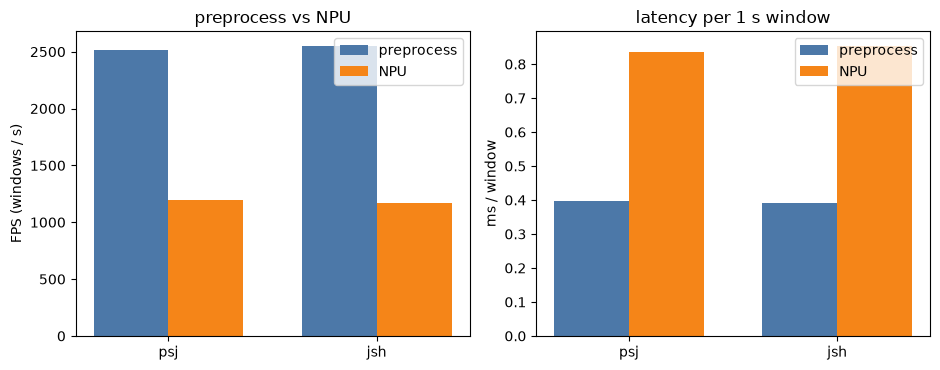

In [8]:
names = [row["name"] for row in report["sets"]]
prep = [row["preprocess_fps"] for row in report["sets"]]
npu = [row["npu_fps"] for row in report["sets"]]
prep_ms = [row["preprocess_ms"] for row in report["sets"]]
npu_ms = [row["npu_ms"] for row in report["sets"]]

print(f"{'set':<8} {'windows':>8} {'preprocess FPS':>16} {'NPU FPS':>10} {'preprocess ms':>14} {'NPU ms':>8}")
for row in report["sets"]:
    print(f"{row['name']:<8} {row['windows']:8d} {row['preprocess_fps']:16.1f} {row['npu_fps']:10.1f} {row['preprocess_ms']:14.2f} {row['npu_ms']:8.2f}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
x = range(len(names))
w = 0.36
axes[0].bar([i - w / 2 for i in x], prep, width=w, label="preprocess", color="#4C78A8")
axes[0].bar([i + w / 2 for i in x], npu, width=w, label="NPU", color="#F58518")
axes[0].set_xticks(list(x), names)
axes[0].set_ylabel("FPS (windows / s)")
axes[0].set_title("preprocess vs NPU")
axes[0].legend()

axes[1].bar([i - w / 2 for i in x], prep_ms, width=w, label="preprocess", color="#4C78A8")
axes[1].bar([i + w / 2 for i in x], npu_ms, width=w, label="NPU", color="#F58518")
axes[1].set_xticks(list(x), names)
axes[1].set_ylabel("ms / window")
axes[1].set_title("latency per 1 s window")
axes[1].legend()
fig.tight_layout()
fig_path = OUT / "fps_preprocess_npu.png"
fig.savefig(fig_path, dpi=120)
print("saved", fig_path)
plt.show()

## Python 전처리와 비교

`features.py`는 최적화 이전의 numpy 전처리입니다. FFT는 numpy `pocketfft`이고, Mel은 64×257 밀행렬입니다. 아래 칸은 같은 창(1.5초는 가운데 1초, 60초 speech는 겹치지 않는 1초)에서 `features()`만 잽니다. C++ 숫자는 위의 `--fps-json` 결과입니다.

처음 만든 C++은 Mel의 0까지 전부 곱하고, FFT 회전 계수를 창마다 다시 계산했습니다. 그 버전은 psj 800창에서 **1.95 ms, 514 FPS**였습니다. jsh는 그 버전으로 다시 재지 않았습니다.

## 어디서 시간을 줄였는지

1. **Mel을 희소 행으로 바꿈.** 필터 하나는 257개 중 일부만 0이 아닙니다. 0이 아닌 구간만 곱합니다. 이 변경으로 첫 C++이 1.95 ms에서 약 0.83 ms가 됐습니다.
2. **FFT를 FFTW double `r2c`로 교체.** `libfftw3.so.3`에 링크하고, 512샘플 plan을 한 번만 만들어 64프레임에 재사용합니다. 헤더는 `/usr/include/fftw3.h`입니다. 직접 짠 스칼라 radix-2를 뺐습니다. 합성 신호 기준 창당 0.81 ms에서 0.40 ms로 줄었습니다. uint8은 `features.py`와 같습니다.
3. **NPU 배치로 직접 기록.** 결과는 uint8 `[64, 64, 3]`에 바로 쓰고 그 포인터를 `Run()`에 넘깁니다. `[3, 64, 64]` 버퍼를 만든 뒤 옮기던 복사는 없습니다.

## 나중에 비동기로 겹칠 때

아래 표의 C++ 전처리와 NPU를 한 스레드에서 이어 하면 창당 시간은 둘의 합입니다. 겹치면 처리율은 더 느린 쪽에 붙고, 창 하나의 지연은 합과 같습니다. FFTW 이후에는 전처리가 NPU보다 짧아서, 겹쳐도 처리율 상한은 NPU입니다.

- 버퍼는 최소 2개. CPU가 `buf[1]`에 `features_u8`를 쓰는 동안 NPU는 `buf[0]`을 읽습니다.
- `RunAsync`가 끝나기 전에 그 버퍼를 덮어쓰면 입력이 깨집니다. `Wait` 이후에만 재사용합니다.
- 창마다 스레드를 만들지 않습니다. 1 ms 안쪽의 일에 스레드 생성 비용이 더 큽니다. 전처리 스레드 하나를 미리 띄웁니다.
- delta는 64개 Mel 프레임이 모두 나온 뒤에 계산됩니다. 창 하나를 코어 여러 개로 쪼개도 끝부분은 한 줄로 남고, 겹침은 창과 창 사이에서 가져갑니다.


set     windows  python ms   python FPS   C++ ms    C++ FPS   NPU ms    NPU FPS
psj         800       0.83       1202.1     0.40     2518.3     0.84     1195.2
jsh        2036       0.96       1037.9     0.39     2551.4     0.85     1171.3
saved /home/kau-2024128055/kau-on-device-final/resnet18_v1/dxnn_test/fps_python_cpp_npu.png


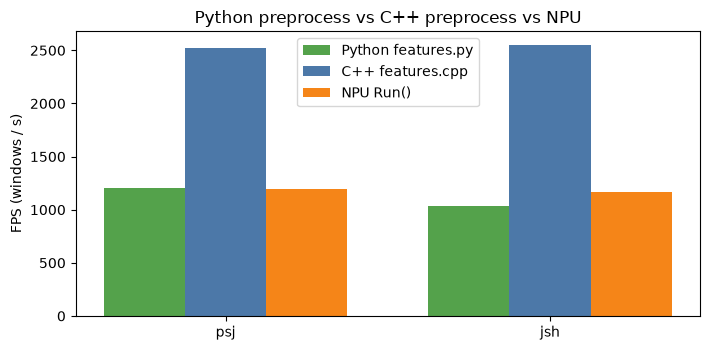

In [9]:
import time, wave
import numpy as np
import features as F

SR, N = 16000, 16000

def load_wav(path):
    with wave.open(str(path)) as w:
        return np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16).copy()

def windows_of(x):
    if len(x) <= N + SR // 2:
        return [F.fit_length(x)]
    n = len(x) // N
    return [x[i * N:(i + 1) * N].astype(np.float32) / 32768.0 for i in range(n)]

def bench_python(folder):
    clips = []
    for name in ["whistle_up", "whistle_down", "tongue_click2", "shh", "clap2", "speech", "background"]:
        d = folder / name
        if not d.is_dir():
            continue
        for path in sorted(d.glob("*.wav")):
            clips.extend(windows_of(load_wav(path)))
    F.features(clips[0])
    t0 = time.perf_counter()
    for clip in clips:
        F.features(clip)
    dt = time.perf_counter() - t0
    return len(clips), dt

py = {folder.name: bench_python(folder) for folder in SETS}
cpp = {row["name"]: row for row in report["sets"]}

print(f"{'set':<6} {'windows':>8} {'python ms':>10} {'python FPS':>12} {'C++ ms':>8} {'C++ FPS':>10} {'NPU ms':>8} {'NPU FPS':>10}")
labels, py_fps, cpp_fps, npu_fps = [], [], [], []
for name in [p.name for p in SETS]:
    n, dt = py[name]
    row = cpp[name]
    py_ms = 1000 * dt / n
    py_rate = n / dt
    print(f"{name:<6} {n:8d} {py_ms:10.2f} {py_rate:12.1f} {row['preprocess_ms']:8.2f} {row['preprocess_fps']:10.1f} {row['npu_ms']:8.2f} {row['npu_fps']:10.1f}")
    labels.append(name)
    py_fps.append(py_rate)
    cpp_fps.append(row["preprocess_fps"])
    npu_fps.append(row["npu_fps"])

fig, ax = plt.subplots(figsize=(7.2, 3.6))
x = range(len(labels))
w = 0.25
ax.bar([i - w for i in x], py_fps, width=w, label="Python features.py", color="#54A24B")
ax.bar(list(x), cpp_fps, width=w, label="C++ features.cpp", color="#4C78A8")
ax.bar([i + w for i in x], npu_fps, width=w, label="NPU Run()", color="#F58518")
ax.set_xticks(list(x), labels)
ax.set_ylabel("FPS (windows / s)")
ax.set_title("Python preprocess vs C++ preprocess vs NPU")
ax.legend()
fig.tight_layout()
cmp_path = OUT / "fps_python_cpp_npu.png"
fig.savefig(cmp_path, dpi=120)
print("saved", cmp_path)
plt.show()
